# 01 · Our helmet photos: what is in the data

**Goal of the project:** look at a photo, find each worker, decide if the worker wears a helmet, and name the helmet color.

This notebook only looks at the helmet photos from the project team, before we train anything. We check:
- whether some photos are duplicated,
- how many photos each color has (class balance),
- on which backgrounds and on which days the photos were taken.

These checks tell us how to test the models later without fooling ourselves.

**Data:** `data/helmets/` (see the README). The 5 classes are the helmet colors. The background is **not** a class.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

REPO = Path.cwd().parent                      # the repository folder (notebooks run from notebooks/)
HELMETS = REPO / "data/helmets"
OUTPUTS = REPO / "outputs"; OUTPUTS.mkdir(exist_ok=True)
SIZE = 224                                    # ResNet50 input size in pixels
COLORS = ["green", "orange", "red", "transparent", "yellow"]

meta = pd.read_csv(HELMETS / "helmets_metadata.csv")
# "All image in the Dataset" holds exact copies (same MD5) of "Cartella", so we use only "Cartella"
photos = meta[meta.dataset_folder == "Cartella DATASET Algoritmo convegno"].reset_index(drop=True)
assert photos.md5.is_unique and set(photos.helmet_color) == set(COLORS)

def load(path):
    im = ImageOps.exif_transpose(Image.open(HELMETS / path)).convert("RGB")  # apply camera rotation; drop PNG alpha
    return np.asarray(im.resize((SIZE, SIZE), Image.BILINEAR), dtype=np.uint8)

## 1. Copies between folders

In [2]:
copies = meta.groupby("md5").agg(n=("dataset_folder", "size"), colors=("helmet_color", "nunique"))
print("rows in the metadata:", len(meta), "| unique images (MD5):", meta.md5.nunique())
print("conflicting labels between copies:", (copies.colors > 1).sum())
meta.groupby("dataset_folder").md5.nunique()

rows in the metadata: 341 | unique images (MD5): 174
conflicting labels between copies: 0


dataset_folder
All image in the Dataset               167
Cartella DATASET Algoritmo convegno    174
Name: md5, dtype: int64

## 2. Class balance

A model trained on unbalanced classes tends to favor the larger class. We will correct this later with class weights and with data augmentation (notebook 03).

In [3]:
n = photos.helmet_color.value_counts().reindex(COLORS)
table = pd.DataFrame({"photos": n, "%": (100 * n / n.sum()).round(1)})
print("largest / smallest class:", round(n.max() / n.min(), 2))
table

largest / smallest class: 1.86


,photos,%
helmet_color,,
green,28,16.1
orange,31,17.8
red,33,19.0
transparent,30,17.2
yellow,52,29.9


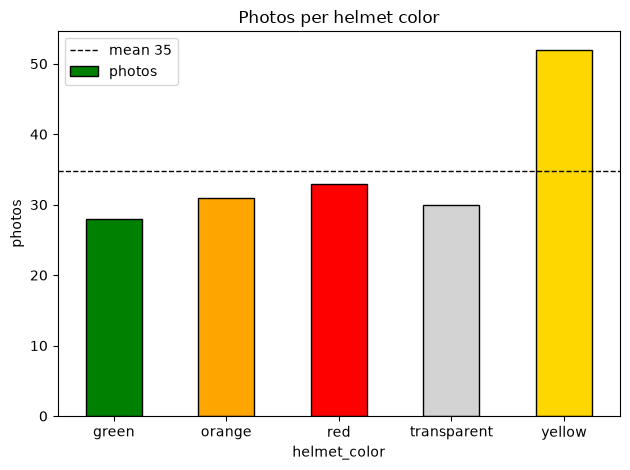

In [4]:
ax = table.photos.plot.bar(color=["green", "orange", "red", "lightgrey", "gold"], edgecolor="black", rot=0)
ax.axhline(n.mean(), ls="--", c="black", lw=1, label=f"mean {n.mean():.0f}")
ax.set_ylabel("photos"); ax.set_title("Photos per helmet color"); ax.legend()
plt.tight_layout(); plt.savefig(OUTPUTS / "01_class_balance.png", dpi=120); plt.show()

## 3. Color × background

Each photo was taken on one of 6 backgrounds. Photos of the same background were taken in bursts and look almost the same. That is why, in notebook 04, we test on one background the model never saw.

In [5]:
cross = pd.crosstab(photos.background, photos.helmet_color).reindex(columns=COLORS)
cross

helmet_color,green,orange,red,transparent,yellow
background,,,,,
black,6,7,7,7,9
floor,6,6,6,6,9
green,0,0,0,0,7
grey,5,5,5,5,9
table,5,6,6,6,9
white,6,7,9,6,9


## 4. Camera and capture date

In [6]:
photos["day"] = photos.capture_datetime.str[:10].fillna("no date (PNG)")
pd.crosstab([photos.camera_model.fillna("unknown"), photos.day], photos.helmet_color).reindex(columns=COLORS)

helmet_color                green  orange  red  transparent  yellow
camera_model day                                                   
EX-Z16       2026-05-14        17      19   19           19       0
iPhone 15    2026-05-14         6       7    9            6       0
             2026-05-15         5       5    5            5       0
             2026-07-08         0       0    0            0      45
unknown      no date (PNG)      0       0    0            0       7

## 5. One example per background and color

In [7]:
X = np.stack([load(p) for p in photos.relative_path])
backgrounds = sorted(photos.background.unique())
fig, axes = plt.subplots(len(backgrounds), len(COLORS), figsize=(10, 2 * len(backgrounds)))
for i, b in enumerate(backgrounds):
    for j, c in enumerate(COLORS):
        ax = axes[i, j]
        ax.set_xticks([]); ax.set_yticks([]); ax.spines[:].set_visible(False)   # not axis("off"): it would hide the row label
        idx = np.where((photos.background == b) & (photos.helmet_color == c))[0]
        if len(idx): ax.imshow(X[idx[0]])
        if i == 0: ax.set_title(c)
        if j == 0: ax.set_ylabel(b)
plt.tight_layout(); plt.savefig(OUTPUTS / "01_examples.png", dpi=120); plt.show()

Figure not saved in this notebook: it shows the private helmet photos. Run the notebook with the data to see it (also saved in outputs/).


## 6. What we learned
- **174 unique photos.** `All image in the Dataset` (167) are exact copies of `Cartella`. No label conflicts.
- **Moderate imbalance:** yellow has 52 photos (30%), the other colors 28 to 33.
- **The green background has only yellow helmets** (7 PNG files without camera data).
- **Yellow was photographed on another day** (July 8, iPhone 15). The other 4 colors were taken on May 14 and 15.
- Green, red and transparent are the same helmet model with a different tint.
- There is **one helmet per color**. A model could learn to recognize *that* helmet instead of its color. Only photos of other helmets can test this.